<a href="https://colab.research.google.com/github/PamellaRob/atividade_telecom/blob/main/U3_atividade_telecom.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade
## Normalização, escalonamento e codificação de dados categóricos
Ciência de Dados · Bacharelado em Engenharia de Software · UNIFSA


### Contexto
Uma operadora de telecomunicações deseja compreender melhor sua base de clientes. A diretoria comercial solicitou à equipe de dados dois produtos:

1. um **índice de valor do cliente**, que permita ranquear os clientes combinando tempo de relacionamento e faturamento;
2. uma **análise do cancelamento (churn)**, que indique quais características dos clientes estão associadas a uma maior taxa de cancelamento.

As métricas disponíveis estão em escalas diferentes e grande parte das informações está em formato textual. Antes de qualquer análise, é necessário preparar os dados.

### Base de dados
IBM. *Telco Customer Churn* (base de exemplo). 7.043 clientes e 21 colunas. Endereço público para carga:

https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv



Aluna: Pamella Roberta dos Santos Silva

Curso: Engenharia de Software (4º período)

Disciplina: Ciência de Dados

In [272]:
# Importações

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Dicionário de dados (colunas utilizadas)
| Coluna | Descrição |
|---|---|
| customerID | identificador do cliente |
| gender | sexo do titular (Male, Female) |
| Partner, Dependents | possui cônjuge; possui dependentes (Yes, No) |
| tenure | tempo de relacionamento, em meses |
| PhoneService, PaperlessBilling | possui telefone; usa fatura digital (Yes, No) |
| MultipleLines | possui múltiplas linhas (Yes, No, No phone service) |
| InternetService | tipo de internet (DSL, Fiber optic, No) |
| OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies | serviços adicionais (Yes, No, No internet service) |
| Contract | tipo de contrato (Month-to-month, One year, Two year) |
| PaymentMethod | forma de pagamento (quatro categorias) |
| MonthlyCharges | valor da mensalidade |
| TotalCharges | valor total faturado desde o início do contrato |
| Churn | o cliente cancelou o serviço no último mês (Yes, No) |

---
## Parte 1 — Carga e preparação dos dados

**1.1** Carregue a base a partir do endereço público informado no início do notebook. Exiba o número de linhas e de colunas e os tipos de cada coluna.

In [230]:
# Carregando base de dados

end = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(end)

In [231]:
# Linhas e colunas
print("Número de linhas e colunas:", df.shape)

print('')

# Tipos de cada coluna
print("Tipos de cada coluna: ")
print(df.dtypes)

Número de linhas e colunas: (7043, 21)

Tipos de cada coluna: 
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


**1.2** A coluna `TotalCharges` deveria ser numérica, mas foi lida como texto. Converta-a para numérico e identifique os registros que não puderam ser convertidos. Examine o valor de `tenure` nesses registros.

In [232]:
# Convertendo a coluna TotalCharges

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [233]:
# Identificando os registros que não puderam ser convertidos

nao_convertidos = df[df['TotalCharges'].isna()]

print("Quantidade não convertida:", len(nao_convertidos))

Quantidade não convertida: 11


In [234]:
# Examinando o valor de tenure nesses registros

print(nao_convertidos[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])
print()
print("Valores de tenure nesses registros:", nao_convertidos["tenure"].unique())

      customerID  tenure  MonthlyCharges  TotalCharges
488   4472-LVYGI       0           52.55           NaN
753   3115-CZMZD       0           20.25           NaN
936   5709-LVOEQ       0           80.85           NaN
1082  4367-NUYAO       0           25.75           NaN
1340  1371-DWPAZ       0           56.05           NaN
3331  7644-OMVMY       0           19.85           NaN
3826  3213-VVOLG       0           25.35           NaN
4380  2520-SGTTA       0           20.00           NaN
5218  2923-ARZLG       0           19.70           NaN
6670  4075-WKNIU       0           73.35           NaN
6754  2775-SEFEE       0           61.90           NaN

Valores de tenure nesses registros: [0]


**1.3** Com base no que foi observado em 1.2, decida como tratar esses registros e implemente a decisão. Justifique a escolha considerando o significado do negócio (o que representa um cliente com esse valor de `tenure`?).

In [235]:
# Tratando os registros

# Preenchendo com 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [236]:
# Conferindo se o tratamendo deu certo

print("Valores Ausentes em TotalCharges:", df["TotalCharges"].isna().sum())
print("Linhas:", df.shape[0])
print(df["TotalCharges"].dtype)

Valores Ausentes em TotalCharges: 0
Linhas: 7043
float64


**Resposta:** Foi escolhido preencher os 11 valores ausentes com 0. Todos esses clientes têm tenure = 0, ou seja, acabaram de contratar o serviço e ainda não receberam nenhuma fatura. Então o valor total faturado até o momento é realmente zero, remover essas linhas jogaria fora clientes reais e preencher com média ou mediana criaria um faturamento que nunca existiu

---
## Parte 2 — Escalonamento e índice de valor do cliente

**2.1** Apresente as estatísticas descritivas de `tenure`, `MonthlyCharges` e `TotalCharges`. Compare as amplitudes (mínimo e máximo) das três métricas.

In [237]:
# Métricas (tenure, MonthlyCharges e TotalCharges)

metricas = ["tenure", "MonthlyCharges", "TotalCharges"]

In [238]:
# Apresentando as estatísticas descritivas
print(df[metricas].describe())

            tenure  MonthlyCharges  TotalCharges
count  7043.000000     7043.000000   7043.000000
mean     32.371149       64.761692   2279.734304
std      24.559481       30.090047   2266.794470
min       0.000000       18.250000      0.000000
25%       9.000000       35.500000    398.550000
50%      29.000000       70.350000   1394.550000
75%      55.000000       89.850000   3786.600000
max      72.000000      118.750000   8684.800000


In [239]:
# Comparando as amplitudes mínimo, máximo e diferença entre eles
amplitude = df[metricas].agg(["min", "max"]).T
amplitude["amplitude"] = amplitude["max"] - amplitude["min"]
print(amplitude)

                  min      max  amplitude
tenure           0.00    72.00       72.0
MonthlyCharges  18.25   118.75      100.5
TotalCharges     0.00  8684.80     8684.8


**Resposta:** Essas métricas estão em escalas muito diferentes. O tenure vai de 0 a 72 meses, o MonthlyCharges vai de 18.25 a 118.75, e TotalCharges vai de 0 a 8684.80. Com isso, vemos que a amplitude de TotalCharges é muito maior que a das outras duas (mais de 100 vezes a de tenure). Isso significa que se somarmos as métricas diretamente, TotalCharges vai pesar muito mais só por ter números maiores, e não por ser mais importante

**2.2** Construa um **índice bruto** somando diretamente as três métricas. Calcule a correlação do índice bruto com cada uma delas. Qual métrica determina o índice? Por quê?

In [240]:
# Índice Bruto

df["indice_bruto"] = df["tenure"] + df["MonthlyCharges"] + df["TotalCharges"]

In [241]:
# Calculando a correlação do índice bruto com cada uma das métricas

correlacoes = df[["indice_bruto", "tenure", "MonthlyCharges", "TotalCharges"]].corr()
print(correlacoes["indice_bruto"])

indice_bruto      1.000000
tenure            0.825752
MonthlyCharges    0.655581
TotalCharges      0.999973
Name: indice_bruto, dtype: float64


**Resposta:** A métrica que determina o índice bruto é TotalCharges, com correlação praticamente igual a 1 com o índice (0.999973). Isso acontece porque as métricas estão em escalas diferentes: TotalCharges tem valores na casa dos milhares, enquanto tenure e MonthlyCharges ficam na casa das dezenas e centenas. Na soma direta, a variação de TotalCharges é muito maior que a das outras duas, então é ela que decide quem fica no topo ou no fim do ranking

**2.3** Padronize as três métricas com **z-score** e construa o **índice padronizado** como a soma das três métricas padronizadas. Repita o cálculo de correlações do item 2.2.

In [242]:
# Padronizando as métricas com z-score
df["tenure_z"] = (df["tenure"] - df["tenure"].mean()) / df["tenure"].std()
df["MonthlyCharges_z"] = (df["MonthlyCharges"] - df["MonthlyCharges"].mean()) / df["MonthlyCharges"].std()
df["TotalCharges_z"] = (df["TotalCharges"] - df["TotalCharges"].mean()) / df["TotalCharges"].std()

In [243]:
# Conferindo
print(df[["tenure_z", "MonthlyCharges_z", "TotalCharges_z"]].describe())

           tenure_z  MonthlyCharges_z  TotalCharges_z
count  7.043000e+03      7.043000e+03    7.043000e+03
mean  -1.614182e-17     -6.456728e-17   -3.934569e-17
std    1.000000e+00      1.000000e+00    1.000000e+00
min   -1.318071e+00     -1.545750e+00   -1.005708e+00
25%   -9.516141e-01     -9.724708e-01   -8.298875e-01
50%   -1.372647e-01      1.857195e-01   -3.905005e-01
75%    9.213896e-01      8.337743e-01    6.647562e-01
max    1.613587e+00      1.794225e+00    2.825605e+00


In [244]:
# Construindo o índice padronizado

df["indice_padronizado"] = df["tenure_z"] + df["MonthlyCharges_z"] + df["TotalCharges_z"]

In [245]:
# Correlações com o índice
print(df[["indice_padronizado", "tenure_z", "MonthlyCharges_z", "TotalCharges_z"]].corr()["indice_padronizado"])

indice_padronizado    1.000000
tenure_z              0.816636
MonthlyCharges_z      0.747730
TotalCharges_z        0.975418
Name: indice_padronizado, dtype: float64


**Resposta:** Depois da padronização, as três métricas passam a ter média 0 e desvio-padrão 1, então entram na soma com pesos comparando. As correlações com o índice ficaram mais equilibradas: tenure_z 0,816, MonthlyCharges_z 0,747 e TotalCharges_z 0,975. Antes o MonthlyCharges tinha 0,66 e o tenure 0,83, e agora a mensalidade pesa bem mais. TotalCharges continua com a maior correlação, mas isso não vem mais da escala

**2.4** Liste os 10 clientes com maior índice bruto e os 10 com maior índice padronizado. Quantos clientes aparecem nas duas listas? O que mudou no perfil dos clientes mais bem posicionados?

In [246]:
# Listando os 10 clientes com maior índice bruto e os 10 com maior índice padronizado

colunas = ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]

# 10 maiores no índice bruto
clientes_bruto = df.sort_values("indice_bruto", ascending=False).head(10)
print(clientes_bruto[colunas + ["indice_bruto"]])

# 10 maiores no índice padronizado
clientes_pad = df.sort_values("indice_padronizado", ascending=False).head(10)
print()
print(clientes_pad[colunas + ["indice_padronizado"]])

      customerID  tenure  MonthlyCharges  TotalCharges  indice_bruto
4610  2889-FPWRM      72          117.80       8684.80       8874.60
4586  7569-NMZYQ      72          118.75       8672.45       8863.20
6768  9739-JLPQJ      72          117.50       8670.10       8859.60
5347  9788-HNGUT      72          116.95       8594.40       8783.35
2187  8879-XUAHX      71          116.25       8564.75       8752.00
6118  9924-JPRMC      72          118.20       8547.15       8737.35
5558  0675-NCDYU      72          116.40       8543.25       8731.65
2368  6650-BWFRT      72          117.15       8529.50       8718.65
2603  0164-APGRB      72          114.90       8496.70       8683.60
2115  8984-HPEMB      71          118.65       8477.60       8667.25

      customerID  tenure  MonthlyCharges  TotalCharges  indice_padronizado
4586  7569-NMZYQ      72          118.75       8672.45            6.227968
4610  2889-FPWRM      72          117.80       8684.80            6.201844
6768  9739-JLPQ

In [247]:
# Quantidade de clientes que aparecem nas duas listas
print("Nas duas listas:", clientes_bruto["customerID"].isin(clientes_pad["customerID"]).sum())

Nas duas listas: 8


**Resposta:** 8 clientes aparecem nas duas listas. No índice bruto, o ranking é decidido quase só pelo TotalCharges, então ficam no topo os clientes com maior faturamento acumulado. No índice padronizado, tenure e MonthlyCharges passam a ter o peso comparável, e a mensalidade conta mais: o cliente 7569-NMZYQ, com a maior mensalidade (118,75), foi para o 1º lugar, e dois clientes com TotalCharges um pouco menor, mas mensalidade alta, entraram no top 10 no lugar de dois com mensalidade mais baixa. Como os dois rankings olham clientes muito antigos (tenure de 71 a 72), as listas ficaram parecidas, porém o critério deixou de depender só do faturamento total

**2.5** Aplique o **min-max** às três métricas e construa um terceiro índice. Compare a ordenação dos clientes no índice min-max com a do índice padronizado (sugestão: correlação entre os dois índices).

In [248]:
# Aplicando o min-max às três métricas

df["tenure_mm"] = (df["tenure"] - df["tenure"].min()) / (df["tenure"].max() - df["tenure"].min())
df["MonthlyCharges_mm"] = (df["MonthlyCharges"] - df["MonthlyCharges"].min()) / (df["MonthlyCharges"].max() - df["MonthlyCharges"].min())
df["TotalCharges_mm"] = (df["TotalCharges"] - df["TotalCharges"].min()) / (df["TotalCharges"].max() - df["TotalCharges"].min())

In [249]:
# Contruindo um terceiro índice
df["indice_minmax"] = df["tenure_mm"] + df["MonthlyCharges_mm"] + df["TotalCharges_mm"]

In [250]:
# Correlação entre o índice min-max e o padronizado
print(df["indice_minmax"].corr(df["indice_padronizado"]))

0.9995152606814915


**Resposta:** A correlação entre o índice min-max e o índice padronizado é de 0,9995, praticamente 1, mostrando que as duas técnicas ordenam os clientes de forma quase idêntica. Tanto o min-max quanto o z-score são transformações lineares, que mudam a escala das métricas mas não a relação de ordem entre os valores. A diferença vem do peso de cada métrica na soma, que não é exatamente o mesmo nas duas técnicas (o min-max usa a amplitude, e o z-score usa o desvio-padrão). Na prática, para este índice, tanto faz usar uma ou outra


**2.6** Calcule a matriz de correlação entre `tenure`, `MonthlyCharges` e `TotalCharges`. Considerando que o faturamento total resulta, aproximadamente, do tempo de relacionamento multiplicado pela mensalidade, discuta se faz sentido manter as três métricas no índice. Proponha e implemente a versão final do índice de valor do cliente.

In [251]:
# Calculando a matriz de correlação entre tenure, MonthlyCharges e TotalCharges

print(df[["tenure", "MonthlyCharges", "TotalCharges"]].corr())

                  tenure  MonthlyCharges  TotalCharges
tenure          1.000000        0.247900      0.826178
MonthlyCharges  0.247900        1.000000      0.651174
TotalCharges    0.826178        0.651174      1.000000


In [252]:
# Versão final do índice: só tenure e MonthlyCharges, padronizadas (colunas _z já estão criadas no 2.3)
df["indice_final"] = df["tenure_z"] + df["MonthlyCharges_z"]

In [253]:
# Verificando os top 10 clientes pelo índice final
print(df.sort_values("indice_final", ascending=False).head(10)[["customerID", "tenure", "MonthlyCharges", "indice_final"]])

      customerID  tenure  MonthlyCharges  indice_final
4586  7569-NMZYQ      72          118.75      3.407811
6118  9924-JPRMC      72          118.20      3.389533
4610  2889-FPWRM      72          117.80      3.376240
3205  3810-DVDQQ      72          117.60      3.369593
6768  9739-JLPQJ      72          117.50      3.366269
2115  8984-HPEMB      71          118.65      3.363771
4155  6904-JLBGY      72          117.35      3.361284
2368  6650-BWFRT      72          117.15      3.354638
5347  9788-HNGUT      72          116.95      3.347991
2025  1488-PBLJN      72          116.85      3.344668


**Resposta:** A matriz feita mostra que TotalCharges tem correlação alta com tenure (0,83) e com MonthlyCharges (0,65), enquanto tenure e MonthlyCharges têm correlação baixa entre si (0,25). Como o faturamento total é aproximadamente o tempo de relacionamento multiplicado pela mensalidade, TotalCharges repete a informação que já está nas outras duas métricas. Manter ela no índice faria o tempo e a mensalidade serem contados duas vezes, dando a eles peso maior do que o pretendido. Com isso, não faz sentido manter as três. Foi proposto um índice final com apenas tenure e MonthlyCharges padronizadas por z-score, somadas Dessa forma, cada informação entra uma vez só, com o mesmo peso, e o índice combina tempo de relacionamento e valor mensal sem redundância

---
## Parte 3 — Forma da distribuição

**3.1** Construa os histogramas das três métricas e calcule a assimetria de cada uma (`.skew()`).

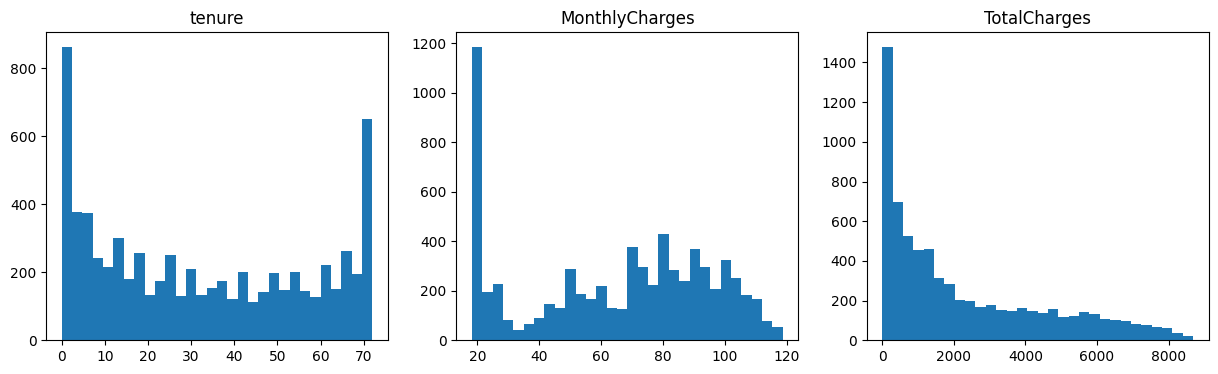

In [254]:
# Construindo os histogramas das três métricas

metricas = ["tenure", "MonthlyCharges", "TotalCharges"]

# histogramas lado a lado
fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
for eixo, col in zip(eixos, metricas):
    eixo.hist(df[col], bins=30)
    eixo.set_title(col)
plt.show()

In [255]:
# Calculando a assimetria de cada uma (.skew())
print(df[metricas].skew())

tenure            0.239540
MonthlyCharges   -0.220524
TotalCharges      0.963235
dtype: float64


**3.2** Aplique a transformação `np.log1p` à coluna `TotalCharges`. Compare o histograma e a assimetria antes e depois da transformação. A transformação logarítmica é adequada para esta coluna? Justifique com base nos valores obtidos.

In [256]:
# Transformação log1p
df["TotalCharges_log"] = np.log1p(df["TotalCharges"])

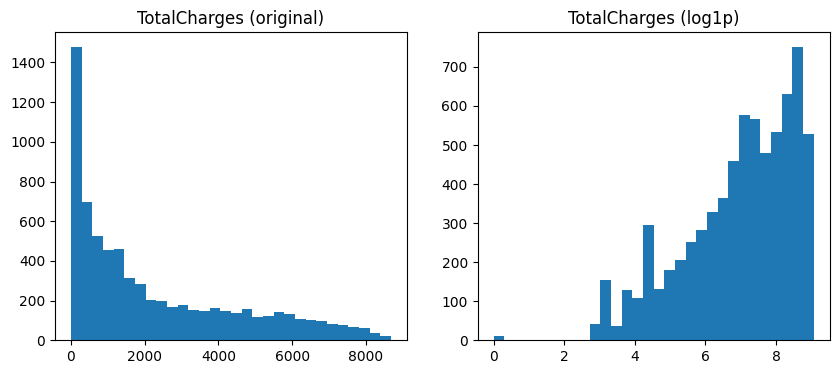

In [257]:
# Comparando o histograma antes e depois da transformação
fig, eixos = plt.subplots(1, 2, figsize=(10, 4))
eixos[0].hist(df["TotalCharges"], bins=30)
eixos[0].set_title("TotalCharges (original)")
eixos[1].hist(df["TotalCharges_log"], bins=30)
eixos[1].set_title("TotalCharges (log1p)")
plt.show()

In [258]:
# Comparando o assimetria antes e depois da transformação
print("Antes:", df["TotalCharges"].skew())
print("Depois:", df["TotalCharges_log"].skew())

Antes: 0.963234654832277
Depois: -0.8244577693814903


**Resposta:** Antes da transformação, a assimetria de TotalCharges era 0,96 (cauda longa à direita), depois do np.log1p, ela passou a -0,82, ou seja, a cauda trocou de lado: agora está à esquerda, com a maior parte dos clientes concentrada em valores altos (entre 6 e 9 na escala log). A assimetria em valor absoluto diminuiu pouco (de 0,96 para 0,82) e o histograma continua assimétrico, então a transformação logarítmica não é adequada para esta coluna. A coluna tem uma distribuição de cauda moderada, não uma cauda extrema como a das avaliações da Steam, e o log comprime demais a parte alta.Por isso, o TotalCharges original, com assimetria de 0,96, ficou mais próximo de uma distribuição aceitável do que o resultado do log

---
## Parte 4 — Codificação das variáveis categóricas

**4.1** Classifique as variáveis abaixo e indique a técnica de codificação adequada, preenchendo a tabela.

| Variável | Tipo (nominal, ordinal ou binária) | Técnica de codificação |
|---|---|---|
| gender | binária | 0 e 1 |
| Partner | binária | 0 e 1 |
| PhoneService | binária | 0 e 1 |
| MultipleLines | nominal | one-hot ou binária |
| InternetService | nominal | one-hot |
| OnlineSecurity | nominal | binária |
| Contract | ordinal | mapeamento ordinal (0, 1, 2) |
| PaymentMethod | nominal | one-hot |
| Churn | binária | 0 e 1 |

**4.2** Converta para 0 e 1 as variáveis binárias `gender`, `Partner`, `Dependents`, `PhoneService`, `PaperlessBilling` e `Churn`.

In [259]:
# Convertendo para 0 e 1 as variáveis binárias gender, Partner, Dependents, PhoneService, PaperlessBilling e Churn

df["Partner"] = df["Partner"].map({"Yes": 1, "No": 0})
df["Dependents"] = df["Dependents"].map({"Yes": 1, "No": 0})
df["PhoneService"] = df["PhoneService"].map({"Yes": 1, "No": 0})
df["PaperlessBilling"] = df["PaperlessBilling"].map({"Yes": 1, "No": 0})
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df["gender"] = df["gender"].map({"Male": 1, "Female": 0})

In [260]:
# Verificando a conversão
print(df[["gender", "Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]].head())
print()
print(df[["gender", "Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]].isna().sum())

   gender  Partner  Dependents  PhoneService  PaperlessBilling  Churn
0       0        1           0             0                 1      0
1       1        0           0             1                 0      0
2       1        0           0             1                 1      1
3       1        0           0             0                 0      0
4       0        0           0             1                 1      1

gender              0
Partner             0
Dependents          0
PhoneService        0
PaperlessBilling    0
Churn               0
dtype: int64


**4.3** As colunas de serviços adicionais (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`) e a coluna `MultipleLines` possuem três valores. Analise o significado de "No internet service" e "No phone service", decida como codificar essas colunas e implemente a decisão.

In [261]:
# Criando a variável com as colunas de serviçi
colunas_servicos = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "MultipleLines"]

In [262]:
# Codificando tudo como binária, 1 para “Yes” e 0 para o resto.
for_linhas = {"Yes": 1, "No": 0, "No internet service": 0, "No phone service": 0}
df["OnlineSecurity"] = df["OnlineSecurity"].map(for_linhas)
df["OnlineBackup"] = df["OnlineBackup"].map(for_linhas)
df["DeviceProtection"] = df["DeviceProtection"].map(for_linhas)
df["TechSupport"] = df["TechSupport"].map(for_linhas)
df["StreamingTV"] = df["StreamingTV"].map(for_linhas)
df["StreamingMovies"] = df["StreamingMovies"].map(for_linhas)
df["MultipleLines"] = df["MultipleLines"].map(for_linhas)

In [263]:
# Verificando
print(df[colunas_servicos].head())
print()
print(df[colunas_servicos].isna().sum())
print()
print(df[colunas_servicos].nunique())

   OnlineSecurity  OnlineBackup  DeviceProtection  TechSupport  StreamingTV  \
0               0             1                 0            0            0   
1               1             0                 1            0            0   
2               1             1                 0            0            0   
3               1             0                 1            1            0   
4               0             0                 0            0            0   

   StreamingMovies  MultipleLines  
0                0              0  
1                0              0  
2                0              0  
3                0              0  
4                0              0  

OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
MultipleLines       0
dtype: int64

OnlineSecurity      2
OnlineBackup        2
DeviceProtection    2
TechSupport         2
StreamingTV         2
StreamingMovies     2
Multiple

**Resposta:** No internet service” e “No phone service” significam que o cliente não possui o serviço-base (internet ou telefone), então ele não tem como contratar os serviços adicionais nem múltiplas linhas. Além disso, a informação de ter ou não internet e telefone já está nas colunas InternetService e PhoneService. Por isso, foi decidido tratar esses dois valores como “No” e codificar as colunas como binárias: 1 para “Yes” e 0 para os demais, evitando criar colunas extras e redundantes

**4.4** Codifique `Contract` de forma ordinal, respeitando a ordem de duração do contrato.

In [264]:
# Codificando Contract

df["Contract"] = df["Contract"].map({"Month-to-month": 0, "One year": 1, "Two year": 2})

In [265]:
# Verificando
print(df["Contract"].value_counts())
print()
print(df["Contract"].isna().sum())

Contract
0    3875
2    1695
1    1473
Name: count, dtype: int64

0


**4.5** Aplique one-hot encoding a `InternetService` e `PaymentMethod`. Utilize ou não o parâmetro `drop_first` e justifique a escolha.

In [266]:
# Aplicando o one-hot encoding a InternetService e PaymentMethod

df = pd.get_dummies(df, columns=["InternetService", "PaymentMethod"], drop_first=True, dtype=int)

In [267]:
# Verificando as novas colunas
print(df.filter(like="InternetService").head())
print()
print(df.filter(like="PaymentMethod").head())
print()
print(df.shape)

   InternetService_Fiber optic  InternetService_No
0                            0                   0
1                            0                   0
2                            0                   0
3                            0                   0
4                            1                   0

   PaymentMethod_Credit card (automatic)  PaymentMethod_Electronic check  \
0                                      0                               1   
1                                      0                               0   
2                                      0                               0   
3                                      0                               0   
4                                      0                               1   

   PaymentMethod_Mailed check  
0                           0  
1                           1  
2                           1  
3                           0  
4                           0  

(7043, 35)


**Resposta:** Foi aplicado o one-hot encoding em InternetService e PaymentMethod, usando drop_first=True. Cada cliente tem apenas uma categoria em cada uma dessas variáveis, então, se todas as colunas de uma variável forem 0, o cliente pertence à categoria removida (DSL em InternetService e Bank transfer (automatic) em PaymentMethod). Assim, a coluna removida é redundante: ela pode ser deduzida das outras, e mantê-la só repetiria informação. O drop_first também evita a colinearidade entre as colunas (a soma delas seria sempre 1), o que atrapalharia a análise de correlação da Parte 5

---
## Parte 5 — Análise do cancelamento para a diretoria comercial

**5.1** Utilizando a coluna `Churn` codificada, calcule a taxa de cancelamento (proporção de clientes que cancelaram) por tipo de contrato, por forma de pagamento e por tipo de internet.

In [268]:
# Calculando a taxa de cancelamento

# Contrato
print("Contrato (0=mensal, 1=um ano, 2=dois anos)")
print(df.groupby("Contract")["Churn"].mean())

# Pagamento
print()
print("Pagamento")
print("Transferência bancária (automática):",
      df[(df["PaymentMethod_Credit card (automatic)"] == 0) &
         (df["PaymentMethod_Electronic check"] == 0) &
         (df["PaymentMethod_Mailed check"] == 0)]["Churn"].mean())
print("Cartão de crédito (automático):", df[df["PaymentMethod_Credit card (automatic)"] == 1]["Churn"].mean())
print("Cheque eletrônico:", df[df["PaymentMethod_Electronic check"] == 1]["Churn"].mean())
print("Cheque pelo correio:", df[df["PaymentMethod_Mailed check"] == 1]["Churn"].mean())

# Internet
print()
print("Internet")
print("DSL:", df[(df["InternetService_Fiber optic"] == 0) & (df["InternetService_No"] == 0)]["Churn"].mean())
print("Fibra ótica:", df[df["InternetService_Fiber optic"] == 1]["Churn"].mean())
print("Sem internet:", df[df["InternetService_No"] == 1]["Churn"].mean())

Contrato (0=mensal, 1=um ano, 2=dois anos)
Contract
0    0.427097
1    0.112695
2    0.028319
Name: Churn, dtype: float64

Pagamento
Transferência bancária (automática): 0.16709844559585493
Cartão de crédito (automático): 0.15243101182654403
Cheque eletrônico: 0.4528541226215645
Cheque pelo correio: 0.19106699751861042

Internet
DSL: 0.1895910780669145
Fibra ótica: 0.4189276485788114
Sem internet: 0.07404980340760157


**5.2** Calcule a correlação entre `Churn` e as demais variáveis codificadas e numéricas. Apresente as cinco variáveis com maior correlação em valor absoluto, indicando o sentido (positivo ou negativo) de cada uma.

In [269]:
# Calculando a correlação entre Churn e as demais variáveis codificadas e numéricas

# Tirando o texto e as colunas criadas nas partes 2 e 3
colunas_drop = ["customerID", "indice_bruto", "tenure_z", "MonthlyCharges_z",
                "TotalCharges_z", "indice_padronizado", "tenure_mm",
                "MonthlyCharges_mm", "TotalCharges_mm", "indice_minmax",
                "indice_final", "TotalCharges_log"]
base = df.drop(columns=colunas_drop)

# Correlação de Churn com todas as outras
corr_churn = base.corr()["Churn"].drop("Churn")

In [270]:
# Mostrando as 5 maiores em valor absoluto
top5 = corr_churn.abs().sort_values(ascending=False).head(5).index
print(corr_churn[top5])

Contract                         -0.396713
tenure                           -0.352229
InternetService_Fiber optic       0.308020
PaymentMethod_Electronic check    0.301919
InternetService_No               -0.227890
Name: Churn, dtype: float64


**5.3** Redija um parágrafo de até oito linhas dirigido à diretoria comercial, com uma recomendação para reduzir o cancelamento. A recomendação deve estar apoiada nos números obtidos em 5.1 e 5.2.

**Resposta:** É recomendado concentrar as ações de retenção nos clientes de contrato mensal e incentivar a migração para contratos de um ou dois anos. A taxa de cancelamento é de 42,7% no contrato mensal, contra 11,3% no de um ano e 2,8% no de dois anos, e Contract é a variável mais associada ao cancelamento (correlação de -0,40). O tempo de relacionamento também pesa (tenure, -0,35): quem fica mais tempo tende a permanecer. Dois grupos merecem atenção especial: clientes com fibra ótica (41,9% de cancelamento) e os que pagam com cheque eletrônico (45,3%), que cancelam muito mais que os demais. Uma ação possível é oferecer desconto na troca do contrato mensal por um anual, priorizando esses dois perfis, e incentivar o pagamento automático (cartão ou transferência, com cerca de 15% a 17% de cancelamento)

---
## Parte 6 — Questões discursivas

**6.1** Explique por que a codificação por rótulo (atribuir os números 0, 1, 2 e 3 às categorias de `PaymentMethod`) seria inadequada para a análise realizada na Parte 5.

**Resposta:** Atribuir 0, 1, 2 e 3 às formas de pagamento seria inadequado porque PaymentMethod é uma variável nominal, sem ordem real. Se fizesse isso, o computador ia entender que uma forma é maior que outra, e na correlação da Parte 5 o resultado mudaria dependendo de qual número eu desse para cada uma. Com o one-hot isso não acontece, porque cada forma de pagamento tem a sua coluna, e deu para ver que o cheque eletrônico é o que mais cancela (45,3%)

**6.2** Descreva uma análise sobre esta base em que o escalonamento das métricas numéricas não alteraria o resultado. Justifique.

**Resposta:** Um exemplo é ranquear os clientes só pela mensalidade (MonthlyCharges), do maior para o menor. O z-score e o min-max mudam a escala, mas não a ordem dos valores, então quem tem a maior mensalidade continua em 1º com ou sem escalonamento. O mesmo vale para a taxa de cancelamento por tipo de contrato da Parte 5, que só usa a média de Churn em cada grupo e não mistura métricas de escalas diferentes. O escalonamento só faria diferença se eu somasse ou comparasse métricas, como no índice da Parte 2

**6.3** O coeficiente de correlação entre `tenure` e `Churn` muda se `tenure` for padronizada por z-score ou escalonada por min-max? Justifique matematicamente e, em seguida, verifique no código.

In [271]:
# Verificando a correlação

print("original:", df["tenure"].corr(df["Churn"]))
print("z-score: ", df["tenure_z"].corr(df["Churn"]))
print("min-max: ", df["tenure_mm"].corr(df["Churn"]))

original: -0.352228670113078
z-score:  -0.3522286701130779
min-max:  -0.35222867011307785


**Resposta:** A correlação não muda. O z-score e o min-max só esticam e deslocam os valores de tenure do mesmo jeito para todos os clientes, na forma x' = a·x + b, com a positivo. Na fórmula da correlação, o a aparece em cima e embaixo e se cancela, e o b não faz diferença. No código, a correlação com Churn deu -0,352 nos três casos (original, z-score e min-max). As diferenças só aparecem lá nas últimas casas decimais, por causa do arredondamento do computador